In [1]:
# Cell 1 — Imports & setup
import sys
from pathlib import Path

# Menambahkan direktori root proyek ke sys.path
sys.path.append(str(Path.cwd().parent))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from src.clustering import (
    compute_elbow,
    plot_elbow,
    compute_silhouette,
    plot_silhouette,
    fit_kmodes,
    plot_mca,
)
from config import (
    PARQUET_DEDUPED,
    PARQUET_CLUSTERED,
    CSV_PROFILES,
    CLUSTER_FEATURES,
    FIGURES_DIR,
    REPORTS_DIR,
)

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

In [2]:
# Cell 2 — Load deduped data
df = pd.read_parquet(PARQUET_DEDUPED)
print(f"Dimensi data yang terbaca : {df.shape}")
print(f"Daftar Kolom             : {list(df.columns)}")
df.head(3)

Dimensi data yang terbaca : (24345, 9)
Daftar Kolom             : ['agent_name', 'rule_id', 'rule_groups', 'rule_description', 'decoder_name', 'level', 'location', 'alert_count', 'hour_group']


,agent_name,rule_id,rule_groups,rule_description,decoder_name,level,location,alert_count,hour_group
0,e-kuesioner,11,stats,None,web-accesslog,4,/var/log/nginx/access.log,1,siang
1,e-kuesioner,11,stats,None,web-accesslog,4,/var/log/nginx/access.log,1,dini_hari
2,e-kuesioner,11,stats,None,web-accesslog,4,/var/log/nginx/access.log,1,malam


In [3]:
# Cell 3 — Siapkan matrix fitur untuk clustering
X = df[CLUSTER_FEATURES].values
print(f"Dimensi matriks fitur (X) : {X.shape}")
print(f"Fitur yang dievaluasi     : {CLUSTER_FEATURES}")

Dimensi matriks fitur (X) : (24345, 6)
Fitur yang dievaluasi     : ['agent_name', 'rule_id', 'decoder_name', 'level', 'location', 'hour_group']


Menghitung Cost untuk Metode Elbow...
K= 2 | cost=39968.00
K= 3 | cost=35568.00
K= 4 | cost=31808.00
K= 5 | cost=26479.00
K= 6 | cost=22480.00
K= 7 | cost=21959.00
K= 8 | cost=18128.00
K= 9 | cost=16750.00
K=10 | cost=15699.00


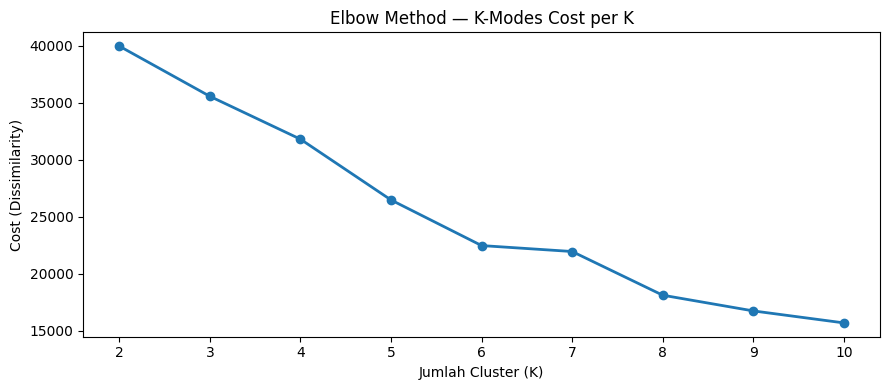

In [4]:
# Cell 4 — Elbow Method
print("Menghitung Cost untuk Metode Elbow...")
costs = compute_elbow(X)

# Visualisasi Elbow
plot_elbow(costs)

Menghitung Koefisien Silhouette Score (Hamming Distance)...
K= 2 | silhouette=0.6135
K= 3 | silhouette=0.5636
K= 4 | silhouette=0.3505
K= 5 | silhouette=0.4988
K= 6 | silhouette=0.5007
K= 7 | silhouette=0.6857
K= 8 | silhouette=0.6692
K= 9 | silhouette=0.6097
K=10 | silhouette=0.6204


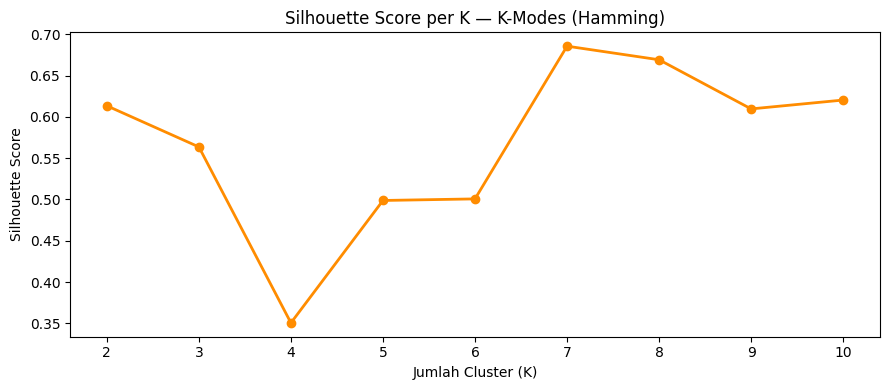

In [5]:
# Cell 5 — Silhouette Score
print("Menghitung Koefisien Silhouette Score (Hamming Distance)...")
silhouette_scores = compute_silhouette(X)

# Visualisasi Silhouette
plot_silhouette(silhouette_scores)

In [6]:
# Cell 6 — Ringkasan pemilihan K optimal
from config import K_RANGE

print("Ringkasan Matriks Evaluasi Pemodelan:")
print(f"{'K':>4} | {'Cost':>10} | {'Silhouette':>12}")
print("-" * 32)
for k, cost, sil in zip(K_RANGE, costs, silhouette_scores):
    sil_str = f"{sil:.4f}" if sil is not None else "    -"
    print(f"{k:>4} | {cost:>10.2f} | {sil_str:>12}")

best_sil_k = list(K_RANGE)[silhouette_scores.index(max(s for s in silhouette_scores if s))]
print(f"\nK dengan Silhouette tertinggi : {best_sil_k}")
print("Silakan konfirmasi titik 'Siku' optimal pada kombinasi grafik di atas.")

Ringkasan Matriks Evaluasi Pemodelan:
   K |       Cost |   Silhouette
--------------------------------
   2 |   39968.00 |       0.6135
   3 |   35568.00 |       0.5636
   4 |   31808.00 |       0.3505
   5 |   26479.00 |       0.4988
   6 |   22480.00 |       0.5007
   7 |   21959.00 |       0.6857
   8 |   18128.00 |       0.6692
   9 |   16750.00 |       0.6097
  10 |   15699.00 |       0.6204

K dengan Silhouette tertinggi : 7
Silakan konfirmasi titik 'Siku' optimal pada kombinasi grafik di atas.


In [7]:
# Cell 7 — Fit model final
# Tentukan K_OPTIMAL dari hasil peninjauan grafik siku dan silhouette score
K_OPTIMAL = 3  

km = fit_kmodes(X, K_OPTIMAL)
df["cluster"] = km.predict(X)

print(f"✓ Sukses memodelkan data dengan K-Modes pada K = {K_OPTIMAL}")
print("\nDistribusi volume data per kelompok cluster:")
print(df["cluster"].value_counts().sort_index())

✓ Sukses memodelkan data dengan K-Modes pada K = 3

Distribusi volume data per kelompok cluster:
cluster
0     6848
1     2702
2    14795
Name: count, dtype: int64


In [8]:
# Cek apakah ada rule_id yang muncul di lebih dari satu cluster
rule_cluster = df.groupby("rule_id")["cluster"].nunique()
rule_multi_cluster = rule_cluster[rule_cluster > 1]

print(f"Total rule_id unik        : {len(rule_cluster)}")
print(f"rule_id di lebih dari 1 cluster : {len(rule_multi_cluster)}")
print("\nDaftar rule_id tersebut:")
print(rule_multi_cluster)

Total rule_id unik        : 50
rule_id di lebih dari 1 cluster : 25

Daftar rule_id tersebut:
rule_id
11       3
19004    3
19007    2
19008    2
19009    2
31104    2
31106    2
31162    2
31164    2
31301    3
31410    2
31514    2
31515    2
31516    2
501      2
503      3
506      2
510      3
52507    3
533      2
550      2
5501     3
5502     3
5715     3
591      2
Name: cluster, dtype: int64


In [9]:
# Cell 8 — Profiling Karakteristik Dominan per Cluster
print("=" * 70)
for cid in sorted(df["cluster"].unique()):
    subset = df[df["cluster"] == cid]
    print(f"\n[PROFIL CLUSTER {cid} — Terdiri dari {len(subset)} Pola Kejadian]")
    print(f"  Modus Rule ID     : {subset['rule_id'].mode()[0]}")
    print(f"  Modus Agent Name  : {subset['agent_name'].mode()[0]}")
    print(f"  Modus Decoder     : {subset['decoder_name'].mode()[0]}")
    print(f"  Modus Level       : {subset['level'].mode()[0]}")
    print(f"  Modus Location    : {subset['location'].mode()[0]}")
    print(f"  Modus Waktu (Jam) : {subset['hour_group'].mode()[0]}")
    print(f"  Total Volume Log Terkompresi di Cluster Ini: {subset['alert_count'].sum():,} baris log")
print("=" * 70)


[PROFIL CLUSTER 0 — Terdiri dari 6848 Pola Kejadian]
  Modus Rule ID     : 31101
  Modus Agent Name  : sads
  Modus Decoder     : web-accesslog
  Modus Level       : 5
  Modus Location    : /var/log/nginx/access.log
  Modus Waktu (Jam) : pagi
  Total Volume Log Terkompresi di Cluster Ini: 363,583 baris log

[PROFIL CLUSTER 1 — Terdiri dari 2702 Pola Kejadian]
  Modus Rule ID     : 31151
  Modus Agent Name  : sads
  Modus Decoder     : web-accesslog
  Modus Level       : 10
  Modus Location    : /var/log/nginx/access.log
  Modus Waktu (Jam) : siang
  Total Volume Log Terkompresi di Cluster Ini: 26,267 baris log

[PROFIL CLUSTER 2 — Terdiri dari 14795 Pola Kejadian]
  Modus Rule ID     : 500554
  Modus Agent Name  : pusatkarir
  Modus Decoder     : syscheck_new_entry
  Modus Level       : 12
  Modus Location    : syscheck
  Modus Waktu (Jam) : dini_hari
  Total Volume Log Terkompresi di Cluster Ini: 32,775 baris log


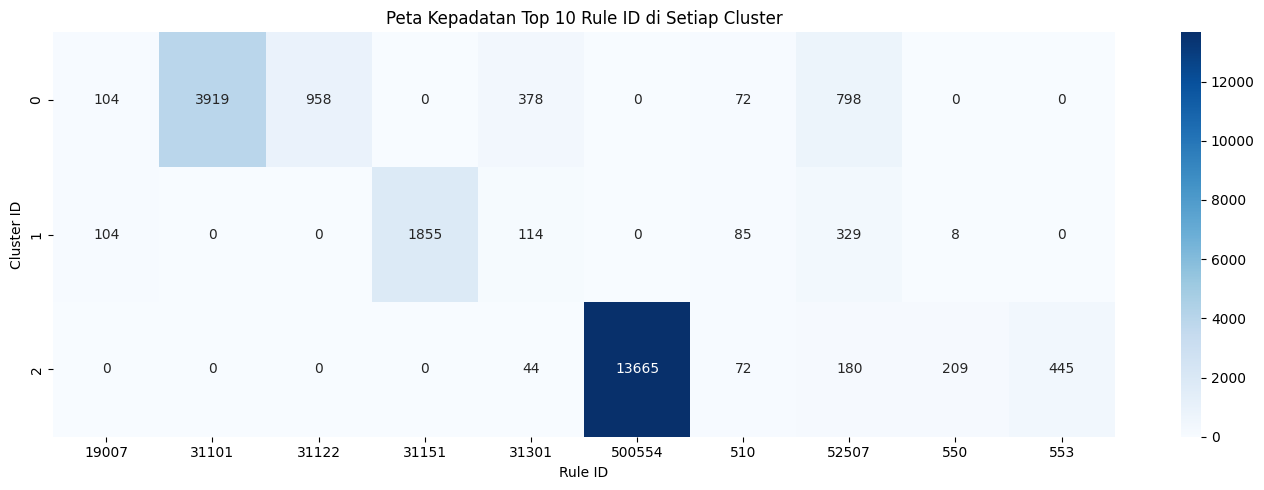

In [10]:
# Cell 9 — Heatmap Distribusi Rule ID per Cluster (Top 10 Rule)
top_rules = df["rule_id"].value_counts().head(10).index
df_top_rules = df[df["rule_id"].isin(top_rules)]
pivot_rule = df_top_rules.groupby(["cluster", "rule_id"]).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(pivot_rule, annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set_title("Peta Kepadatan Top 10 Rule ID di Setiap Cluster")
ax.set_xlabel("Rule ID")
ax.set_ylabel("Cluster ID")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "heatmap_rule_cluster.png", dpi=150)
plt.show()

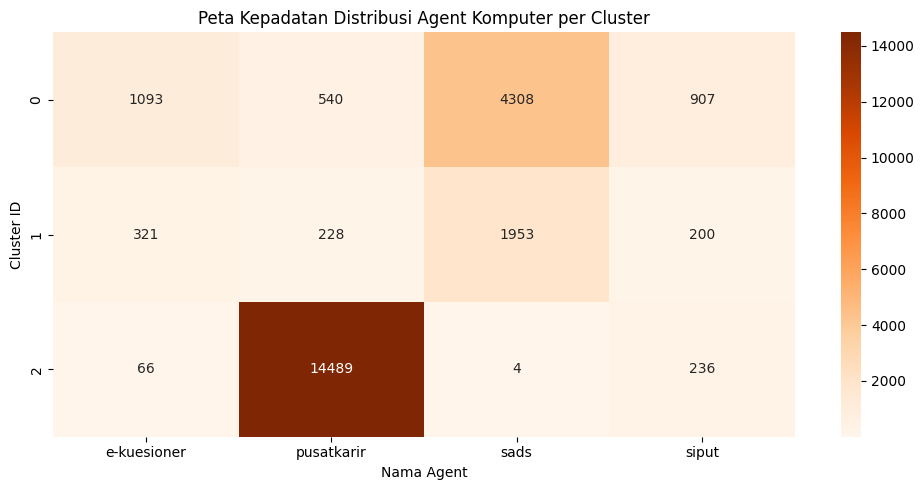

In [11]:
# Cell 10 — Heatmap Distribusi Nama Agent per Cluster
pivot_agent = df.groupby(["cluster", "agent_name"]).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(pivot_agent, annot=True, fmt="d", cmap="Oranges", ax=ax)
ax.set_title("Peta Kepadatan Distribusi Agent Komputer per Cluster")
ax.set_xlabel("Nama Agent")
ax.set_ylabel("Cluster ID")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "heatmap_agent_cluster.png", dpi=150)
plt.show()

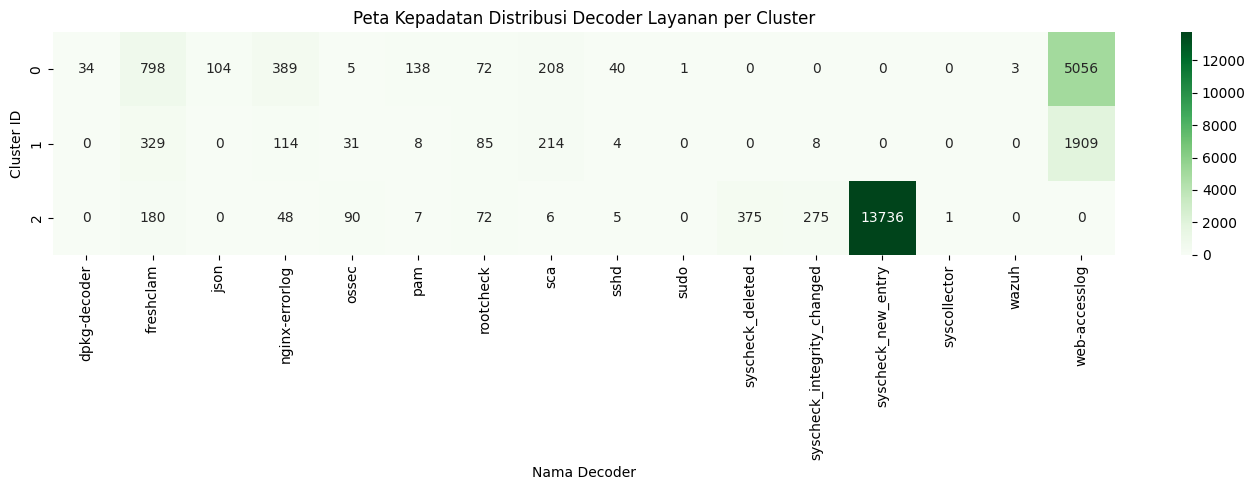

In [12]:
# Cell 11 — Heatmap Distribusi Decoder per Cluster
pivot_decoder = df.groupby(["cluster", "decoder_name"]).size().unstack(fill_value=0)

fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(pivot_decoder, annot=True, fmt="d", cmap="Greens", ax=ax)
ax.set_title("Peta Kepadatan Distribusi Decoder Layanan per Cluster")
ax.set_xlabel("Nama Decoder")
ax.set_ylabel("Cluster ID")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "heatmap_decoder_cluster.png", dpi=150)
plt.show()

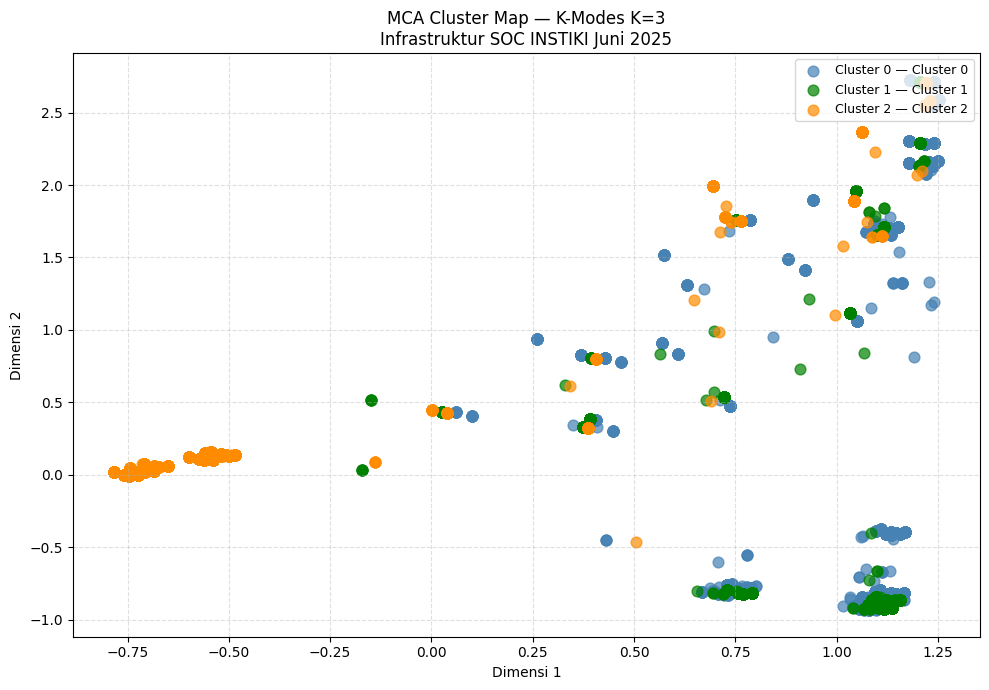

Variance explained per dimensi MCA:
  Dimensi 1 : 5.35%
  Dimensi 2 : 4.55%
  Total     : 9.90%


In [13]:
# Cell 12 — MCA Cluster Map
# Membuat label dinamis mengikuti jumlah K_OPTIMAL yang dipilih
CLUSTER_LABELS = {i: f"Cluster {i}" for i in range(K_OPTIMAL)}

# Palet warna dasar untuk pembeda spasial klaster
base_colors = ["steelblue", "green", "darkorange", "red", "purple", "brown", "pink", "gray", "olive", "cyan"]
CLUSTER_COLORS = {i: base_colors[i % len(base_colors)] for i in range(K_OPTIMAL)}

plot_mca(
    df=df,
    cluster_labels=CLUSTER_LABELS,
    cluster_colors=CLUSTER_COLORS,
    title=f"MCA Cluster Map — K-Modes K={K_OPTIMAL}\nInfrastruktur SOC INSTIKI Juni 2025",
    filename="mca_cluster_map.png",
)

In [14]:
# Cell 13 — Eksportasi Karakteristik Profil Cluster ke Berkas CSV laporan
profiles = []
for cid in sorted(df["cluster"].unique()):
    subset = df[df["cluster"] == cid]
    profiles.append({
        "cluster":          cid,
        "n_pola_kejadian":  len(subset),
        "rule_id_modus":    subset["rule_id"].mode()[0],
        "agent_modus":      subset["agent_name"].mode()[0],
        "decoder_modus":    subset["decoder_name"].mode()[0],
        "level_modus":      subset["level"].mode()[0],
        "location_modus":   subset["location"].mode()[0],
        "waktu_modus":      subset["hour_group"].mode()[0],
        "total_volume_log": subset["alert_count"].sum(),
        "rekomendasi_tuning": "",  # Diisi manual (contoh: abaikan / buat threshold / ringkas)
        "tingkat_prioritas":  "",  # Diisi manual (contoh: Rendah / Sedang / Tinggi)
    })

df_profiles = pd.DataFrame(profiles)
print("=== STRUKTUR TABEL PROFIL CLUSTER SIAP SIMPAN ===")
print(df_profiles.to_string(index=False))

df_profiles.to_csv(CSV_PROFILES, index=False)
print(f"\n✓ Berkas sukses diekspor ke: {CSV_PROFILES}")

=== STRUKTUR TABEL PROFIL CLUSTER SIAP SIMPAN ===
 cluster  n_pola_kejadian rule_id_modus agent_modus      decoder_modus  level_modus            location_modus waktu_modus  total_volume_log rekomendasi_tuning tingkat_prioritas
       0             6848         31101        sads      web-accesslog            5 /var/log/nginx/access.log        pagi            363583                                     
       1             2702         31151        sads      web-accesslog           10 /var/log/nginx/access.log       siang             26267                                     
       2            14795        500554  pusatkarir syscheck_new_entry           12                  syscheck   dini_hari             32775                                     

✓ Berkas sukses diekspor ke: e:\Aditya\Lecture\TUGAS-AKHIR\Clustering_Wazuh\reports\cluster_profiles.csv


In [15]:
# Cell 14 — Simpan clustered data
df.to_parquet(PARQUET_CLUSTERED, index=False)
print(f"Clustered data sukses diamankan ke : {PARQUET_CLUSTERED}")
print(f"Matriks dimensi akhir data proyek : {df.shape}")

Clustered data sukses diamankan ke : e:\Aditya\Lecture\TUGAS-AKHIR\Clustering_Wazuh\data\processed\clustered.parquet
Matriks dimensi akhir data proyek : (24345, 10)


In [16]:
agents_fokus = ["sads", "pusatkarir", "e-kuesioner", "siput"]
df_fokus = df[df["agent_name"].isin(agents_fokus)].copy()

for cid in sorted(df_fokus["cluster"].unique()):
    subset = df_fokus[df_fokus["cluster"] == cid]
    total = len(subset)
    print(f"\n{'='*50}")
    print(f"CLUSTER {cid} — Total {total} pola")
    print(f"{'='*50}")
    
    # Dominasi rule_groups
    print(f"\nDistribusi rule_groups:")
    groups_dist = subset["rule_groups"].value_counts()
    for groups, count in groups_dist.head(10).items():
        pct = count/total*100
        print(f"  {groups}: {count} ({pct:.1f}%)")
    
    # Dominasi rule_id
    print(f"\nTop 5 rule_id:")
    rule_dist = subset["rule_id"].value_counts()
    for rule, count in rule_dist.head(5).items():
        pct = count/total*100
        print(f"  rule_id {rule}: {count} ({pct:.1f}%)")


CLUSTER 0 — Total 6848 pola

Distribusi rule_groups:
  web,accesslog,attack: 3964 (57.9%)
  web,accesslog,system_error: 960 (14.0%)
  clamd,freshclam,virus: 798 (11.7%)
  nginx,web: 378 (5.5%)
  sca: 208 (3.0%)
  vulnerability-detector: 104 (1.5%)
  web,appsec,attack: 93 (1.4%)
  pam,syslog: 73 (1.1%)
  ossec,rootcheck: 72 (1.1%)
  pam,syslog,authentication_success: 64 (0.9%)

Top 5 rule_id:
  rule_id 31101: 3919 (57.2%)
  rule_id 31122: 958 (14.0%)
  rule_id 52507: 798 (11.7%)
  rule_id 31301: 378 (5.5%)
  rule_id 19007: 104 (1.5%)

CLUSTER 1 — Total 2702 pola

Distribusi rule_groups:
  web,accesslog,web_scan,recon: 1855 (68.7%)
  clamd,freshclam,virus: 329 (12.2%)
  sca: 214 (7.9%)
  nginx,web: 114 (4.2%)
  ossec,rootcheck: 85 (3.1%)
  ossec: 30 (1.1%)
  web,appsec,attack: 26 (1.0%)
  web,accesslog,attack: 16 (0.6%)
  ossec,syscheck,syscheck_entry_modified,syscheck_file: 8 (0.3%)
  web,accesslog,system_error: 5 (0.2%)

Top 5 rule_id:
  rule_id 31151: 1855 (68.7%)
  rule_id 52507: 32